# Loading and evaluating fitted (explicit) spline surfaces

A **fitted spline surface** on SplineCloud is an explicit function $y = f(x_1, x_2)$: a
tensor-product B-spline fitted to the points of a *bivariate relation* (`dr2_...`). Unlike a
lofted surface (a parametric surface through a stack of curves), it is evaluated directly at
$(x_1, x_2)$ - no inversion of a parametric map is needed.

`load_spline_surface` returns an `ExplicitSplineSurface` for these surfaces (requires
splinecloud-scipy >= 1.5.0 and scipy >= 1.12). This notebook walks through three of them:

1. a surface fitted to a **grid table** (x2 values in the column headers);
2. a **friction factor chart** fitted with a logarithmic Reynolds number axis;
3. a **measured height map** - scattered points - used for optimization.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from splinecloud_scipy import load_spline_surface

%matplotlib inline

In [2]:
def describe(surf):
    """A short summary of a fitted surface: what it models and how well it fits."""
    acc = surf.accuracy or {}
    print(f"{surf.name} ({surf.uid}) of '{surf.relation_name}' ({surf.relation_uid})")
    print(f"  y = f(x1, x2):  {surf.y_label} = f({surf.x1_label}, {surf.x2_label})")
    print(f"  scales:         {surf.scales}")
    print(f"  degree:         {surf.k},  control points: {surf.shape}")
    for name, (lo, hi) in zip((surf.x1_label, surf.x2_label), surf.domain):
        print(f"  domain {name}: [{lo:.6g}, {hi:.6g}]")
    print(f"  fit:            {surf.method}, status '{surf.fit_status}', "
          f"R2 = {acc.get('r2', float('nan')):.4f}, RMSE = {acc.get('rmse', float('nan')):.4g}"
          f" over {acc.get('n')} points")

## 1. A surface fitted to a grid table

`srf_vw09p6gpmNrD` was fitted to a table with $u$ down the first column, $v$ in the column
headers and $Y$ in the cells.

In [3]:
surf = load_spline_surface("srf_vw09p6gpmNrD")
describe(surf)

Spline Surface 1 (srf_vw09p6gpmNrD) of 'Bivariate Relation Example - 2D dense grid fit' (dr2_Kx4w0I2CuVw5)
  y = f(x1, x2):  Y = f(u, v)
  scales:         ['Linear', 'Linear', 'Linear']
  degree:         (3, 3),  control points: (15, 15)
  domain u: [0, 1]
  domain v: [0, 2]
  fit:            rmtb, status 'ok', R2 = 0.9984, RMSE = 0.01401 over 2400 points


`load_data()` returns the points the surface was fitted to, one `[x1, x2, y]` row per point.
Grid tables are melted into one point per filled cell (`surf.data_format == "matrix"`);
`surf.excluded_points` is the relation's exclusion mask (`None` when nothing is excluded).

In [4]:
labels, data = surf.load_data()
print(labels, data.shape, surf.data_format, surf.excluded_points)

['u', 'v', 'Y'] (2400, 3) matrix None


### Evaluate on a grid

`eval_grid(x1_vals, x2_vals)` evaluates the outer product of the two axes and returns `Y`
with shape `(len(x1_vals), len(x2_vals))`.

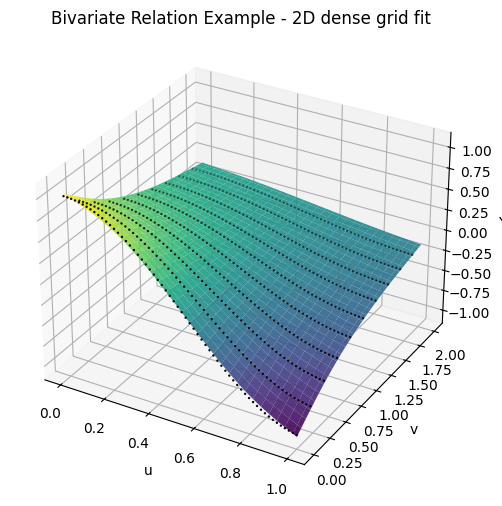

In [5]:
(u_lo, u_hi), (v_lo, v_hi) = surf.domain
u_vals = np.linspace(u_lo, u_hi, 60)
v_vals = np.linspace(v_lo, v_hi, 60)

Y = surf.eval_grid(u_vals, v_vals)
U, V = np.meshgrid(u_vals, v_vals, indexing="ij")

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(U, V, Y, cmap="viridis", linewidth=0, antialiased=True, alpha=0.9)
ax.scatter(data[::4, 0], data[::4, 1], data[::4, 2], marker=".", color="black", s=2)
ax.set_xlabel(surf.x1_label)
ax.set_ylabel(surf.x2_label)
ax.set_zlabel(surf.y_label)
ax.set_title(surf.relation_name)
plt.show()

### Evaluate at scattered points

The surface is callable with NumPy broadcasting, `surf(x1, x2)`, and `eval_points(points)`
takes an `(n, 2)` array. Here the residuals at the data points reproduce the fit accuracy
reported by the platform.

In [6]:
print("f(0.5, 1.0) =", surf(0.5, 1.0))

residuals = surf.eval_points(data[:, :2]) - data[:, 2]
print(f"RMSE at the data points: {np.sqrt(np.mean(residuals**2)):.6f}  "
      f"(platform: {surf.accuracy['rmse']:.6f})")

f(0.5, 1.0) = 0.025459910724320408


RMSE at the data points: 0.014007  (platform: 0.014007)


### Slices: curves at a fixed input

`slice({axis: value})` fixes one input and returns the exact univariate spline of the other
one - here $Y(u)$ along three columns of the table (the table's $v$ values).

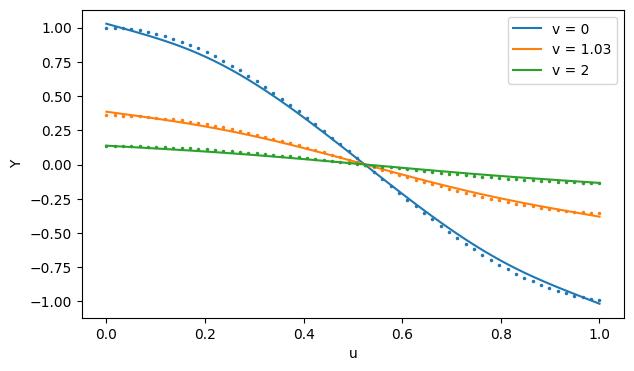

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for v in np.unique(data[:, 1])[[0, len(np.unique(data[:, 1])) // 2, -1]]:
    curve = surf.slice({1: v})                 ## y(u) at this v
    line, = ax.plot(u_vals, curve(u_vals), label=f"{surf.x2_label} = {v:.3g}")
    column = data[np.isclose(data[:, 1], v)]
    ax.plot(column[:, 0], column[:, 2], ".", color=line.get_color(), ms=3)
ax.set_xlabel(surf.x1_label)
ax.set_ylabel(surf.y_label)
ax.legend()
plt.show()

### Outside the domain: extrapolation policies

Points outside the fitted domain give `NaN` by default (`"none"`). Pass an `extrapolate`
policy for other behaviour: `"clamp"` (the value at the nearest domain point), `"linear"`
(first-order Taylor from the nearest domain point) or `"polynomial"` (continue the edge
polynomial pieces). The default can also be set at load time:
`load_spline_surface(uid, extrapolation="linear")`.

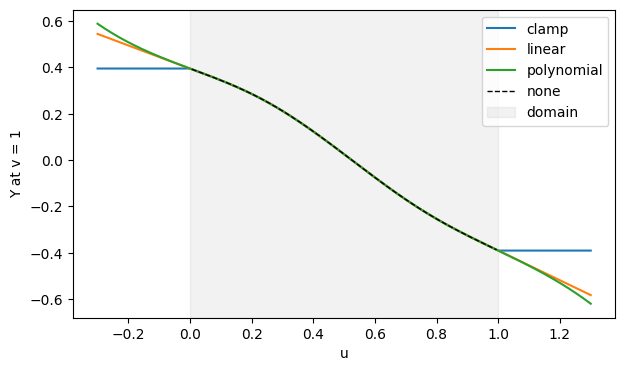

In [8]:
v_mid = (v_lo + v_hi) / 2
u_ext = np.linspace(u_lo - 0.3, u_hi + 0.3, 200)
points = np.column_stack([u_ext, np.full_like(u_ext, v_mid)])

fig, ax = plt.subplots(figsize=(7, 4))
for policy in ("clamp", "linear", "polynomial"):
    ax.plot(u_ext, surf.eval_points(points, extrapolate=policy), label=policy)
## "none": NaN outside the domain, so the line stops at its edges
ax.plot(u_ext, surf.eval_points(points, extrapolate="none"), "k--", lw=1, label="none")
ax.axvspan(u_lo, u_hi, color="grey", alpha=0.1, label="domain")
ax.set_xlabel(surf.x1_label)
ax.set_ylabel(f"{surf.y_label} at {surf.x2_label} = {v_mid:g}")
ax.legend()
plt.show()

## 2. A friction factor chart with a logarithmic axis

`srf_PeVUk8LUsP3y` models the Darcy friction factor as a function of the Reynolds number
(logarithmic axis) and the relative roughness. The spline is fitted in $\log_{10}(Re)$, but
every call takes and returns **physical values** - no manual log transform is needed.

In [9]:
surf = load_spline_surface("srf_PeVUk8LUsP3y")
describe(surf)
print("log axes (x1, x2):", surf.log_x, " log y:", surf.log_y)

labels, data = surf.load_data()
print(data.shape, surf.data_format)

Spline Surface 1 (srf_PeVUk8LUsP3y) of 'Bivariate Relation Exapmle - 2D fit with log axis' (dr2_7t9KysVqdRlD)
  y = f(x1, x2):  Friction factor = f(Re, Relative roughness)
  scales:         ['Logarithmic', 'Linear', 'Linear']
  degree:         (3, 3),  control points: (15, 15)
  domain Re: [3167.3, 9.88333e+06]
  domain Relative roughness: [1.00397e-05, 0.0309529]
  fit:            rmtb, status 'ok', R2 = 0.9921, RMSE = 0.001128 over 800 points
log axes (x1, x2): [ True False]  log y: False


(800, 3) vector


Slices at a few roughness values give the familiar chart: friction factor over $Re$ on a
logarithmic axis, with the data points coloured by roughness.

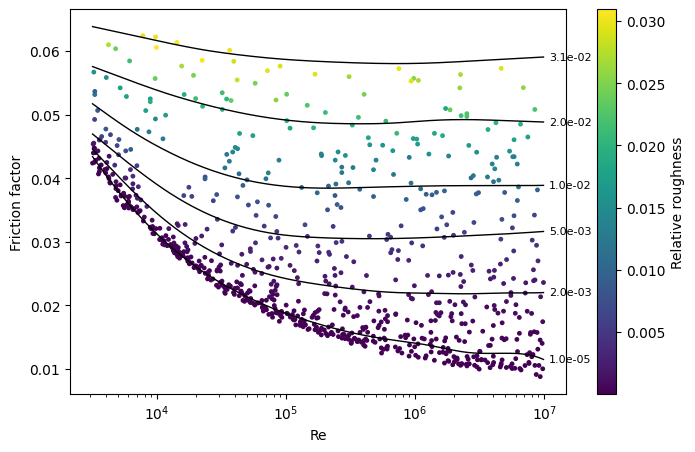

In [10]:
(re_lo, re_hi), (eps_lo, eps_hi) = surf.domain
re_vals = np.geomspace(re_lo, re_hi, 300)

fig, ax = plt.subplots(figsize=(8, 5))
points = ax.scatter(data[:, 0], data[:, 2], c=data[:, 1], cmap="viridis", s=6)
for eps in (eps_lo, 2e-3, 5e-3, 1e-2, 2e-2, eps_hi):
    ax.plot(re_vals, surf.slice({1: eps})(re_vals), color="black", lw=1)
    ax.annotate(f"{eps:.1e}", (re_hi, surf(re_hi, eps)), fontsize=8,
                xytext=(4, 0), textcoords="offset points", va="center")
ax.set_xscale("log")
ax.set_xlabel(surf.x1_label)
ax.set_ylabel(surf.y_label)
plt.colorbar(points, ax=ax, label=surf.x2_label)
plt.show()

### Gradients

`grad(points)` returns $\partial y / \partial x_i$ in physical units, here checked against
central finite differences.

In [11]:
point = np.array([[1e5, 0.005]])
g = surf.grad(point)[0]

h = np.array([1.0, 1e-6])                     ## steps in Re and roughness
fd = [(surf(*(point[0] + dx)) - surf(*(point[0] - dx))) / (2 * dx[i])
      for i, dx in enumerate(np.diag(h))]
print("grad:        ", g)
print("finite diff.:", np.array(fd))

grad:         [-9.82924305e-09  1.94594718e+00]
finite diff.: [-9.82924304e-09  1.94594718e+00]


## 3. A measured height map: scattered points and optimization

`srf_pRuZ7t952RuC` was fitted to scattered height measurements of a surface patch.

In [12]:
surf = load_spline_surface("srf_pRuZ7t952RuC")
describe(surf)

labels, data = surf.load_data()
residuals = surf.eval_points(data[:, :2]) - data[:, 2]

Spline Surface 1 (srf_pRuZ7t952RuC) of 'Bivariate Relation Example - 2D fit to scattered data' (dr2_Ix93LPhmf3SA)
  y = f(x1, x2):  Height (um) = f(x (mm), y (mm))
  scales:         ['Linear', 'Linear', 'Linear']
  degree:         (3, 3),  control points: (12, 12)
  domain x (mm): [-2.9929, 2.9968]
  domain y (mm): [-2.9989, 2.993]
  fit:            rmtb, status 'ok', R2 = 0.9787, RMSE = 0.2918 over 1500 points


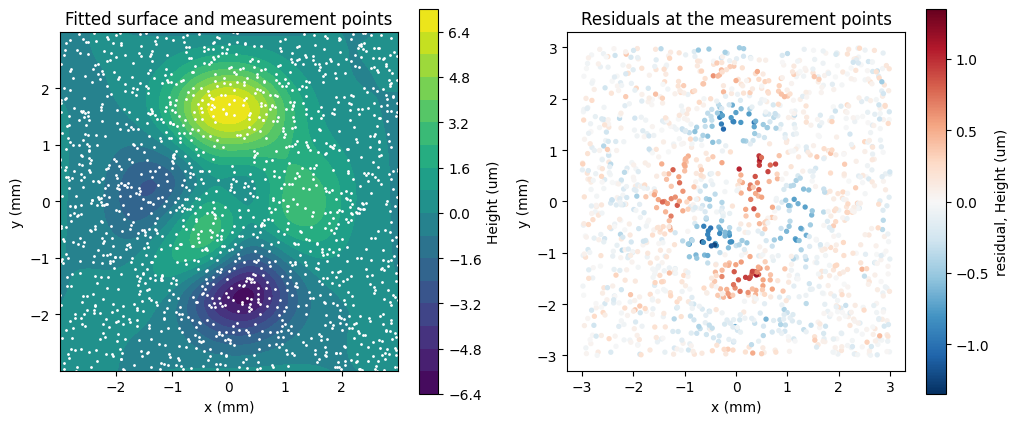

In [13]:
(x_lo, x_hi), (y_lo, y_hi) = surf.domain
x_vals = np.linspace(x_lo, x_hi, 120)
y_vals = np.linspace(y_lo, y_hi, 120)
H = surf.eval_grid(x_vals, y_vals)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5))
filled = ax0.contourf(x_vals, y_vals, H.T, levels=20, cmap="viridis")
ax0.plot(data[:, 0], data[:, 1], ".", color="white", ms=2)
plt.colorbar(filled, ax=ax0, label=surf.y_label)
ax0.set_title("Fitted surface and measurement points")

limit = np.abs(residuals).max()
spots = ax1.scatter(data[:, 0], data[:, 1], c=residuals, cmap="RdBu_r", s=8,
                    vmin=-limit, vmax=limit)
plt.colorbar(spots, ax=ax1, label=f"residual, {surf.y_label}")
ax1.set_title("Residuals at the measurement points")
for ax in (ax0, ax1):
    ax.set_xlabel(surf.x1_label)
    ax.set_ylabel(surf.x2_label)
    ax.set_aspect("equal")
plt.show()

### Finding the highest and the lowest point

The surface is smooth and its gradient is exact, so a gradient-based optimizer converges in a
few iterations. Each search starts from the highest (lowest) measurement and stays inside the
domain (`bounds`).

In [14]:
bounds = surf.domain.tolist()

def find_extremum(sign):
    """sign = +1: the peak, -1: the pit."""
    def objective(xy):
        value = surf(*xy)
        gradient = surf.grad(np.atleast_2d(xy))[0]
        return -sign * value, -sign * gradient
    start = data[np.argmax(sign * data[:, 2]), :2]
    return minimize(objective, x0=start, jac=True, bounds=bounds, method="L-BFGS-B")

peak, pit = find_extremum(+1), find_extremum(-1)
for name, res in (("peak", peak), ("pit", pit)):
    print(f"{name}: {surf.y_label} = {surf(*res.x):.4f} at {surf.x1_label} = {res.x[0]:.4f}, "
          f"{surf.x2_label} = {res.x[1]:.4f}  ({res.nit} iterations)")

peak: Height (um) = 7.1347 at x (mm) = -0.0129, y (mm) = 1.6349  (5 iterations)
pit: Height (um) = -5.9118 at x (mm) = 0.2706, y (mm) = -1.6805  (5 iterations)


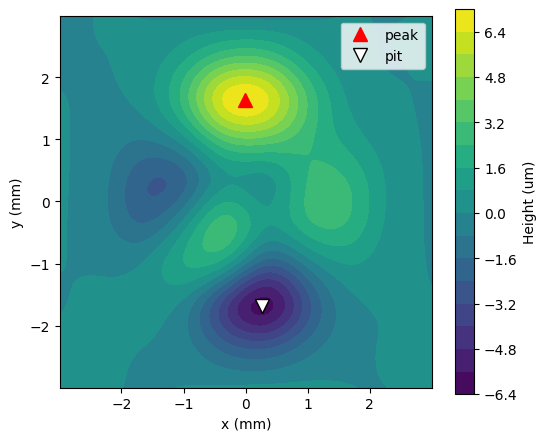

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
filled = ax.contourf(x_vals, y_vals, H.T, levels=20, cmap="viridis")
ax.plot(*peak.x, "r^", ms=10, label="peak")
ax.plot(*pit.x, "wv", ms=10, mec="black", label="pit")
plt.colorbar(filled, ax=ax, label=surf.y_label)
ax.set_xlabel(surf.x1_label)
ax.set_ylabel(surf.x2_label)
ax.set_aspect("equal")
ax.legend()
plt.show()

## Compatibility with lofted surfaces

`ExplicitSplineSurface` keeps the evaluation calls of lofted surfaces (`SplineSurface`), so
code written for those works unchanged: `eval(x1, x2)` gives a scalar for scalar inputs and
the grid `X1, X2, Y` for arrays, and `compute_gradients=True` adds the derivatives.

In [16]:
h, (dh_dx1, dh_dx2) = surf.eval(0.5, -0.5, compute_gradients=True)
print(f"{surf.y_label} = {h:.4f}, d/d{surf.x1_label} = {dh_dx1:.4f}, "
      f"d/d{surf.x2_label} = {dh_dx2:.4f}")

X1, X2, Y = surf.eval(np.linspace(-1, 1, 5), np.linspace(-1, 1, 3))
print(X1.shape, X2.shape, Y.shape)

Height (um) = 0.5279, d/dx (mm) = 0.9626, d/dy (mm) = 3.3389
(5, 3) (5, 3) (5, 3)
